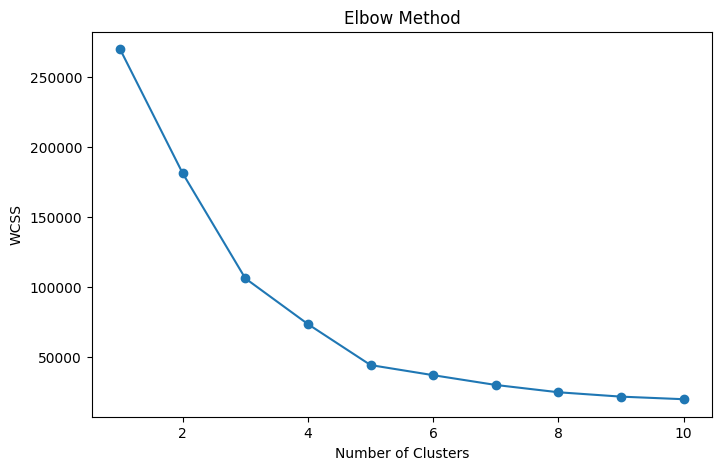

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  


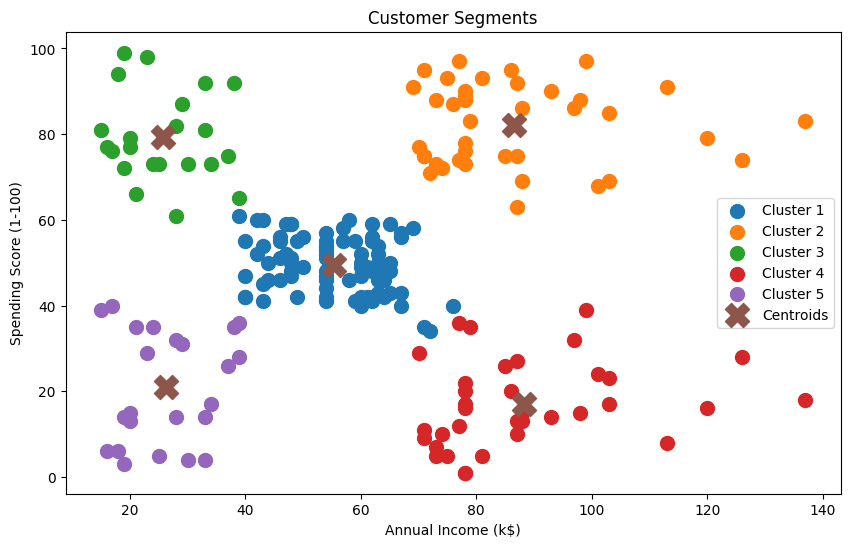

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load Dataset
df = pd.read_csv("/content/Mall_Customers.csv")

# Select Features for Clustering
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Find Optimal Number of Clusters using Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

# Apply K-Means (Optimal K = 5)
kmeans = KMeans(n_clusters=5, init='k-means++',
                random_state=42, n_init=10)

y_kmeans = kmeans.fit_predict(X)

# Add Cluster Labels to Dataset
df['Cluster'] = y_kmeans

# Display First Few Records
print(df.head())

# Visualize Clusters
plt.figure(figsize=(10,6))

plt.scatter(X.iloc[y_kmeans == 0, 0],
            X.iloc[y_kmeans == 0, 1],
            s=100, label='Cluster 1')

plt.scatter(X.iloc[y_kmeans == 1, 0],
            X.iloc[y_kmeans == 1, 1],
            s=100, label='Cluster 2')

plt.scatter(X.iloc[y_kmeans == 2, 0],
            X.iloc[y_kmeans == 2, 1],
            s=100, label='Cluster 3')

plt.scatter(X.iloc[y_kmeans == 3, 0],
            X.iloc[y_kmeans == 3, 1],
            s=100, label='Cluster 4')

plt.scatter(X.iloc[y_kmeans == 4, 0],
            X.iloc[y_kmeans == 4, 1],
            s=100, label='Cluster 5')

# Plot Centroids
plt.scatter(kmeans.cluster_centers_[:,0],
            kmeans.cluster_centers_[:,1],
            s=300, marker='X',
            label='Centroids')

plt.title('Customer Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()